# Triton的向量加法实验

在这里，我们基于官方，然后修改block_size的大小，来观察不同block_size对性能的影响。

In [1]:
import torch

import triton
import triton.language as tl

DEVICE = triton.runtime.driver.active.get_active_torch_device()


@triton.jit
def add_kernel(x_ptr,  # *Pointer* to first input vector.
               y_ptr,  # *Pointer* to second input vector.
               output_ptr,  # *Pointer* to output vector.
               n_elements,  # Size of the vector.
               BLOCK_SIZE: tl.constexpr,  # Number of elements each program should process.
               # NOTE: `constexpr` so it can be used as a shape value.
               ):
    # There are multiple 'programs' processing different data. We identify which program
    # we are here:
    pid = tl.program_id(axis=0)  # We use a 1D launch grid so axis is 0.
    # This program will process inputs that are offset from the initial data.
    # For instance, if you had a vector of length 256 and block_size of 64, the programs
    # would each access the elements [0:64, 64:128, 128:192, 192:256].
    # Note that offsets is a list of pointers:
    block_start = pid * BLOCK_SIZE
    offsets = block_start + tl.arange(0, BLOCK_SIZE)
    # Create a mask to guard memory operations against out-of-bounds accesses.
    mask = offsets < n_elements
    # Load x and y from DRAM, masking out any extra elements in case the input is not a
    # multiple of the block size.
    x = tl.load(x_ptr + offsets, mask=mask)
    y = tl.load(y_ptr + offsets, mask=mask)
    output = x + y
    # Write x + y back to DRAM.
    tl.store(output_ptr + offsets, output, mask=mask)

在这里，我们给add函数增加了一个block_size参数，来控制每个block的大小。

In [2]:
def add(x: torch.Tensor, y: torch.Tensor, block_size: int):
    # We need to preallocate the output.
    output = torch.empty_like(x)
    assert x.device == DEVICE and y.device == DEVICE and output.device == DEVICE
    n_elements = output.numel()
    # The SPMD launch grid denotes the number of kernel instances that run in parallel.
    # It is analogous to CUDA launch grids. It can be either Tuple[int], or Callable(metaparameters) -> Tuple[int].
    # In this case, we use a 1D grid where the size is the number of blocks:
    grid = lambda meta: (triton.cdiv(n_elements, meta['BLOCK_SIZE']),)
    # NOTE:
    #  - Each torch.tensor object is implicitly converted into a pointer to its first element.
    #  - `triton.jit`'ed functions can be indexed with a launch grid to obtain a callable GPU kernel.
    #  - Don't forget to pass meta-parameters as keywords arguments.
    add_kernel[grid](x, y, output, n_elements, BLOCK_SIZE=block_size)
    # We return a handle to z but, since `torch.cuda.synchronize()` hasn't been called, the kernel is still
    # running asynchronously at this point.
    return output

In [4]:
torch.manual_seed(0)
size = 98432
x = torch.rand(size, device=DEVICE)
y = torch.rand(size, device=DEVICE)
output_torch = x + y
output_triton = add(x, y, block_size=1024)
print(output_torch)
print(output_triton)
print(f'The maximum difference between torch and triton is '
      f'{torch.max(torch.abs(output_torch - output_triton))}')

tensor([1.3713, 1.3076, 0.4940,  ..., 0.9592, 0.3409, 1.2567], device='cuda:0')
tensor([1.3713, 1.3076, 0.4940,  ..., 0.9592, 0.3409, 1.2567], device='cuda:0')
The maximum difference between torch and triton is 0.0


In [5]:
for block_size in [128, 256, 512, 1024]:
    output_triton = add(x, y, block_size)
    torch.testing.assert_close(output_triton, x + y)
    print(f"BLOCK_SIZE={block_size}: PASS")

BLOCK_SIZE=128: PASS
BLOCK_SIZE=256: PASS
BLOCK_SIZE=512: PASS
BLOCK_SIZE=1024: PASS


# benchmark不同block_size的性能

In [6]:
@triton.testing.perf_report(
    triton.testing.Benchmark(
        x_names=['size'],  # Argument names to use as an x-axis for the plot.
        x_vals=[2 ** i for i in range(12, 28, 1)],  # Different possible values for `x_name`.
        x_log=True,  # x axis is logarithmic.
        line_arg='block_size',  # Argument name to use as a line in the plot.
        line_vals=[128,256, 512, 1024],  # Different possible values for `line_arg`.
        line_names=['block_size=128', 'block_size=256', 'block_size=512', 'block_size=1024'],  # Label names for the lines.
        styles=[('blue', '-'), ('green', '-'), ('red', '-'), ('orange', '-')],  # Line styles.
        ylabel='GB/s',  # Label name for the y-axis.
        plot_name='vector-add-blocksize',  # Name for the plot. Used also as a file name for saving the plot.
        args={},  # Values for function arguments not in `x_names` and `y_name`.
    ))
def benchmark(size, block_size):
    x = torch.rand(size, device=DEVICE, dtype=torch.float32)
    y = torch.rand(size, device=DEVICE, dtype=torch.float32)
    quantiles = [0.5, 0.2, 0.8]




    ms, min_ms, max_ms = triton.testing.do_bench(lambda: add(x, y, block_size=block_size), quantiles=quantiles)
    gbps = lambda ms: 3 * x.numel() * x.element_size() * 1e-9 / (ms * 1e-3)
    return gbps(ms), gbps(max_ms), gbps(min_ms)

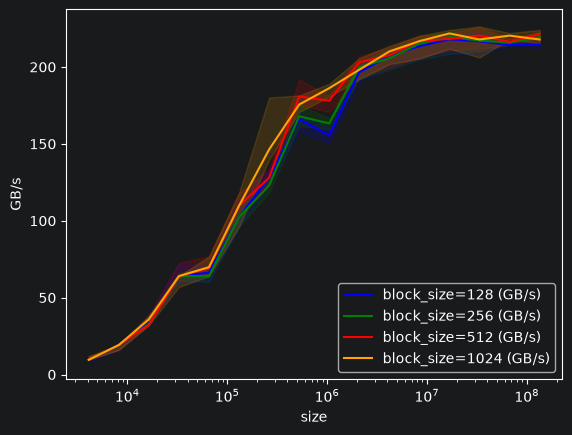

vector-add-blocksize:
           size  block_size=128 (GB/s)  block_size=256 (GB/s)  block_size=512 (GB/s)  block_size=1024 (GB/s)
0        4096.0               9.600000               9.600000               9.600000                9.600000
1        8192.0              19.200000              19.200000              19.200000               19.200000
2       16384.0              34.133333              32.855615              32.336841               35.825072
3       32768.0              63.999998              63.999998              63.999998               63.999998
4       65536.0              66.242587              63.999998              69.033707               69.818181
5      131072.0             102.400003             102.400003             109.714284              109.714284
6      262144.0             127.999995             122.880003             127.999995              146.285715
7      524288.0             166.054047             167.969251             180.705879              175.5428

In [9]:
benchmark.run(show_plots=True, print_data=True)